---
---

# ESTIMATION AND INFERENCE

---
---

## ROADMAP: where we've been, and where we're going

Recently, we've been discussing **exploratory data analysis**, which is used to answer descriptive and exploratory questions by investigating datasets to summarize their main characteristics, uncover underlying relationships, and spot anomalies, primarily using statistical summaries and data visualization.

And at the time, we applied the various analysis tools and visualization techniques to explore the data at hand. 

But now we're going to take an important step and acknowledge that most data we have access to is just a *subset* of the data we'd like to draw conclusions about. We will revisit the ideas of **statistical inference** and begin to investigate this topic more thoroughly. 

---
---

## About the Data: Titanic Survival

<div style="text-align: center;">
<img src="https://www.currentaffairs.org/hubfs/Imported_Blog_Media/titanicii-1024x646-1.jpg" alt="target-study-sample" width="700"/>
</div>

[Image Source](https://www.currentaffairs.org/news/2021/10/how-the-titanic-haunts-us)

The RMS Titanic was a massive British passenger ocean liner (the largest of its time) that was widely celebrated as an engineering marvel and deemed practically unsinkable. On its maiden voyage in April 1912, the ship carried over 2,200 passengers and crew from Southampton, England, toward New York City. Striking an iceberg in the North Atlantic, the vessel suffered catastrophic hull damage and sank within hours. Because the ship lacked enough lifeboats for everyone on board, roughly 1,500 people lost their lives in one of history's deadliest commercial maritime disasters.

Available for us to study is a dataset containing an anonymized passenger list that includes several variables for each passenger, including one that indicates whether the person survived the sinking of the Titanic on April 15, 1912. The data is available in `titanic_passenger_info.csv` on both LEARN and [here on GitHub](https://github.com/ntstevens/DATSC101/blob/main/data/titanic_passenger_info.csv). The data in its raw form comes from [this R package](https://search.r-project.org/CRAN/refmans/DALEX/html/titanic.html).


For each of 2207 passengers and crew, we have information on the following 9 variables:

* `gender`: a categorical variable with labels `male` and `female`.

* `age`: a numeric variable specifying the person's age on the day of the sinking.

* `class`: a categorical variable specifying the class for passengers or the type of service aboard for crew members.

* `embarked`: a categorical variable representing the person's place of of embarkment (Belfast/Cherbourg/Queenstown/Southampton).

* `country`: a categorical variable representing the person's home country.

* `fare`: a numeric variable specifying the ticket price (`0` for crew members, musicians and employees of the shipyard company).

* `sibsp`: a numeric variable specifying the number if siblings/spouses aboard.

* `parch`: a numeric variable specifying the number of parents/children aboard.

* `survived`: a categorical variable with two labels (`no` and `yes`) specifying whether the person has survived the sinking.

We have information on all passengers&mdash;so we have the whole *population*&mdash;but we'll use this data to illustrate the potential complications that arise when performing analyses on *samples* from the population. 

---

### Titanic EDA 

First we read-in the data, examine the first few rows, and summarize the contents of the columns.

In [28]:
import pandas as pd
import numpy as np
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [29]:
titanic = pd.read_csv("https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/titanic_passenger_info.csv")
titanic.head(20)

,gender,age,class,embarked,country,fare,sibsp,parch,survived
0,male,42.000000,3rd,Southampton,United States,7.1100,0.0,0.0,no
1,male,13.000000,3rd,Southampton,United States,20.0500,0.0,2.0,no
2,male,16.000000,3rd,Southampton,United States,20.0500,1.0,1.0,no
3,female,39.000000,3rd,Southampton,England,20.0500,1.0,1.0,yes
4,female,16.000000,3rd,Southampton,Norway,7.1300,0.0,0.0,yes
5,male,25.000000,3rd,Southampton,United States,7.1300,0.0,0.0,yes
6,male,30.000000,2nd,Cherbourg,France,24.0000,1.0,0.0,no
7,female,28.000000,2nd,Cherbourg,France,24.0000,1.0,0.0,yes
8,male,27.000000,3rd,Cherbourg,Lebanon,18.1509,0.0,0.0,yes
9,male,20.000000,3rd,Southampton,Finland,7.1806,0.0,0.0,yes


In [30]:
titanic.describe(include = "all")

,gender,age,class,embarked,country,fare,sibsp,parch,survived
count,2207,2205.000000,2207,2207,2126,2181.000000,2197.000000,2197.000000,2207
unique,2,NaN,7,4,48,NaN,NaN,NaN,2
top,male,NaN,3rd,Southampton,England,NaN,NaN,NaN,no
freq,1718,NaN,709,1616,1125,NaN,NaN,NaN,1496
mean,NaN,30.436735,NaN,NaN,NaN,19.773290,0.297223,0.229404,NaN
std,NaN,12.159677,NaN,NaN,NaN,43.402454,0.840384,0.694232,NaN
min,NaN,0.166667,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN
25%,NaN,22.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN
50%,NaN,29.000000,NaN,NaN,NaN,7.150600,0.000000,0.000000,NaN
75%,NaN,38.000000,NaN,NaN,NaN,20.110600,0.000000,0.000000,NaN


### Passenger Demographics

Let's begin by exploring what kinds of passengers were on the the Titanic. Below we tabulate the number of passengers that were recorded as `male` vs. `female`. We see that there were many more (3.5 times as many) males aboard the Titanic than females.

In [31]:
titanic["gender"].value_counts()

gender
male      1718
female     489
Name: count, dtype: int64

Next we explore the `age` of the passengers. We see that the average age was 30.44 years with half of passengers between 22 and 38 years old. The eldest person was 74 and we see that there were many children and babies aboard as well.

In [32]:
titanic["age"].describe()

count    2205.000000
mean       30.436735
std        12.159677
min         0.166667
25%        22.000000
50%        29.000000
75%        38.000000
max        74.000000
Name: age, dtype: float64

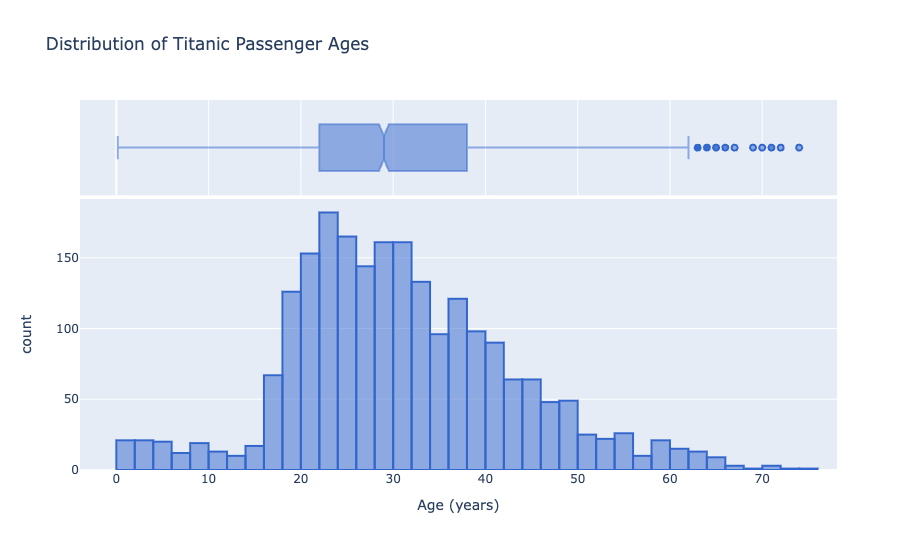

In [33]:
fig = px.histogram(titanic["age"], marginal = "box", height = 550,
                   labels = {"value":"Age (years)"},
                   title = "Distribution of Titanic Passenger Ages")
fig.update_traces(showlegend = False, 
                  marker_color = "rgba(51, 102, 204, 0.5)", 
                  marker_line_color = "rgba(51, 102, 204, 1.0)",
                  marker_line_width = 2)

Next let's explore the different passenger types (i.e., their `class`). We see there were three ticket classes (`1st`, `2nd`, `3rd`) and together this accounts for 1317 of the people on the Titanic. The remaining 890 people on board were crew members of various types.

In [34]:
titanic["class"].value_counts().sort_index()

class
1st                 324
2nd                 284
3rd                 709
deck crew            66
engineering crew    324
restaurant staff     69
victualling crew    431
Name: count, dtype: int64

### Survival Rates
**What proportion of people survived the sinking of the Titanic?**

We find that the *survival rate* is only 0.322157. That is, about 32\% of passengers and crew survived and 68\% died.

In [35]:
titanic["survived"].value_counts(normalize = True)

survived
no     0.677843
yes    0.322157
Name: proportion, dtype: float64

**How does the survival rate change as a function of ticket class?**

The table and bar chart below demonstrate that 1st class passengers and deck crew had much higher survival rates than other passenger types. 

In [36]:
pd.crosstab(titanic["class"], titanic["survived"], normalize = "index")

survived,no,yes
class,,
1st,0.379630,0.620370
2nd,0.584507,0.415493
3rd,0.744711,0.255289
deck crew,0.348485,0.651515
engineering crew,0.780864,0.219136
restaurant staff,0.956522,0.043478
victualling crew,0.781903,0.218097


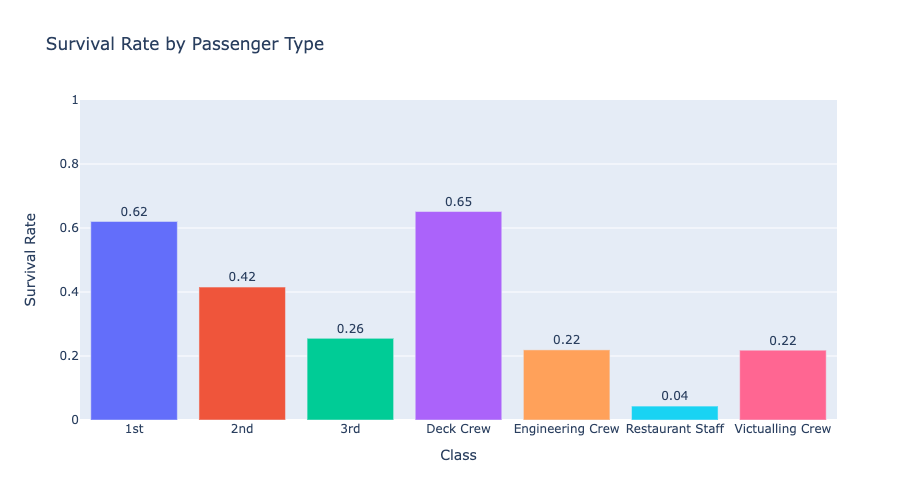

In [80]:
# Extract survival rate by class
surv_by_class = pd.crosstab(titanic["survived"], titanic["class"], normalize = "columns").loc["yes"]
surv_by_class = surv_by_class.reset_index(drop = True)

# Create a rounded version of the rates for plotting
surv_rate_round = np.round(surv_by_class, 2)

# Construct a new Series with customize class labels
classes = pd.Series(["1st", "2nd", "3rd", "Deck Crew", "Engineering Crew", "Restaurant Staff", "Victualling Crew"])

# Construct a new DataFrame with survival rates by class
surv_by_class = pd.DataFrame({"Class":classes, "Survival Rate":surv_by_class})

# Make a bar chart of the survival rates by class
fig = px.bar(surv_by_class,
             x = "Class", y = "Survival Rate", color = "Class",
             title = "Survival Rate by Passenger Type",
            range_y = [0,1],
            text = surv_rate_round,
            height = 500)
fig.update_traces(textposition="outside", showlegend = False)

However, the proportions can be somewhat misleading. There were far fewer deck crew than other passenger types, so while their survival rate is high, the number of deck crew who survived is not high. See the alternative presentation of these data below, which tabulates and visualizes raw counts as opposed to proportions. This reinforces that you were best off if you were a 1st class passenger.

In [38]:
pd.crosstab(titanic["class"], titanic["survived"])

survived,no,yes
class,,
1st,123,201
2nd,166,118
3rd,528,181
deck crew,23,43
engineering crew,253,71
restaurant staff,66,3
victualling crew,337,94


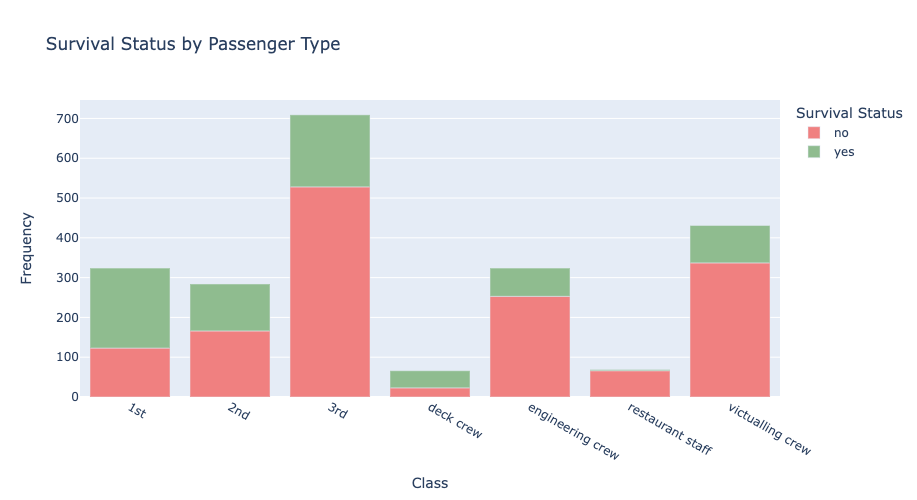

In [39]:
px.bar(pd.crosstab(titanic["class"], titanic["survived"]),
       labels = {"value":"Frequency",
                 "class":"Class",
                 "survived":"Survival Status"},
       color_discrete_sequence = ["lightcoral","darkseagreen"],
       title = "Survival Status by Passenger Type",
       height=500)

**How does the survival rate change as a function of gender?**

The  chart below demonstrate that while there were many more male passengers than female, females were more likely to live (in terms of survival rate), and more females lived (in terms of raw counts). This is largely owed to the "women and children first" rule when filling lifeboats.

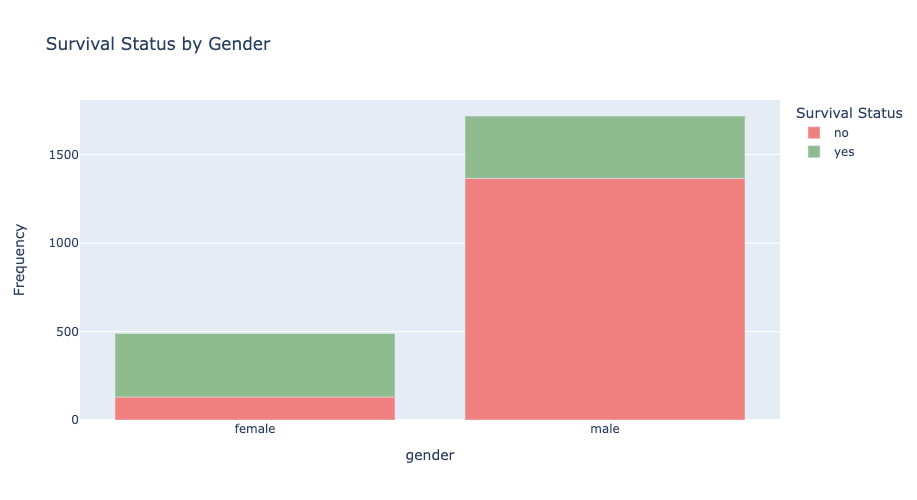

In [40]:
px.bar(pd.crosstab(titanic["gender"], titanic["survived"]),
       labels = {"value":"Frequency",
                 "class":"Gender",
                 "survived":"Survival Status"},
       color_discrete_sequence = ["lightcoral","darkseagreen"],
       title = "Survival Status by Gender",
       height=500, width = 700)

**How does the survival rate change for children vs. adults?**

Let's further explore the "women and children first" rule. In particular, let's look at survival as a function of age. Specifically, survival as a function of whether or not you were a child.

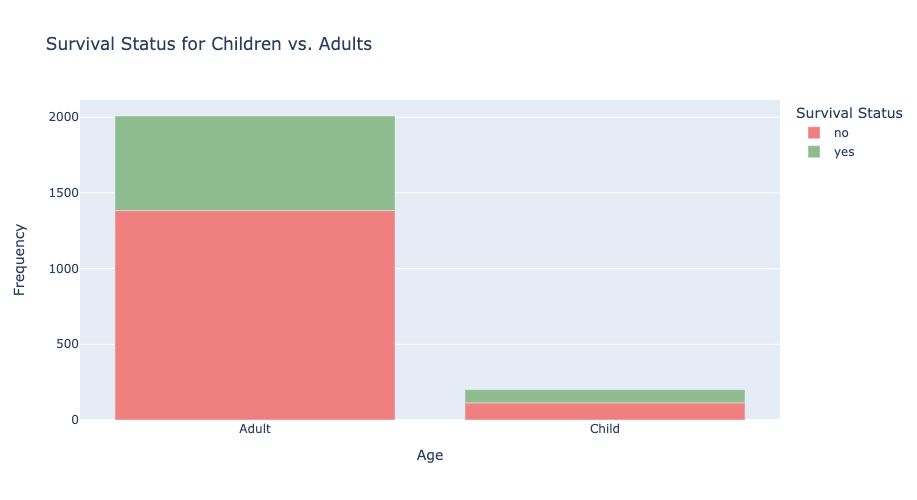

In [41]:
# Create a new variable that indicates whether someone is a child (under 18 years old)
is_child = titanic["age"] < 18
titanic["is_child"] = is_child.map({True: "Child", False: "Adult"})

# Make a stacked bar chat to visualize survical status for children vs. adults
px.bar(pd.crosstab(titanic["is_child"], titanic["survived"]),
       labels = {"value":"Frequency",
                 "is_child":"Age",
                 "survived":"Survival Status"},
       color_discrete_sequence = ["lightcoral","darkseagreen"],
       title = "Survival Status for Children vs. Adults",
       height=500, width = 700)

In [42]:
pd.crosstab(titanic["is_child"], titanic["survived"], normalize = "index")

survived,no,yes
is_child,,
Adult,0.689088,0.310912
Child,0.565000,0.435000


While there were far fewer children than adults, we see that about 44\% of children survived while only 31\% of adults did. So, it seems children were indeed given priority seating on lifeboats.

---
---

## The Path of Inductive Inference

We've seen a graphic like the one below before. We discussed the ideas of **samples** versus **populations** back when discussing the "Plan" stage of PPDAC.

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/path_of_inference.svg" alt="path-of-inference" width="580"/>
</div>

**Recall:**

* The **target population** is the collection of units we would like to draw conclusions about.
* The **study population** is the collection of units we're actually able to study. Sometimes this is the same as the target population.
    * **study error** exists when there is a meaningful difference between the target population and the study population. 
* The **sample** is the subset of the study population we collect data from.
    * **sample error** exists when there is a meaningful difference between the study population and the sample. 

The new component of this graphic is the arrow connecting "Recorded Data" to "Target Population". This arrow closes the loop on the the **path of inductive inference**:

* *Inductive* reasoning is a bottom-up logic method that starts with specific observations and moves to broader general conclusions. 
* When we perform **statistical inference** we use inductive reasoning: we use sample data to draw conclusions about the broader target population.
* The quality of inference relies on reducing study error, sample error, and measurement error. We've already discussed these errors and strategies to mitigate them. But we now take a more in-depth look at sample error.


---
---

## Samples and Sample Error

To formalize our discussion of inference, it will be helpful to define some notation:
* Let $\mathcal{S}$ represent the *sample* of units we have access to.
* Let $\mathcal{P}$ represent the *population* from which the sample is drawn. This is necessarily the study population, which in some cases is also the target population.

In practice we don't have access to all of the population $\mathcal{P}$, and we think of the sample $\mathcal{S}$ as a proxy for $\mathcal{P}$.

In statistical terms we think of $\mathcal{S}$ as an **estimate** of $\mathcal{P}$. In statistical notation, we might write $\mathcal{S}=\widehat{\mathcal{P}}$. The circumflex is called a *hat* and it distingues an estimate from the estimated quantity. For instance:
* $\mathcal{P}$ denotes a population
* $\widehat{\mathcal{P}}$ denotes an *estimate* of the population

Ultimately, we are interested in **attributes** of the population. Recall, attributes are characteristics of the population we'd like to know about. 
* In the Titanic data we have access to the entire population of passengers. 
* Summaries calculated on this population, like *average age*, or *survival rate* are examples of attributes.

However, when all we have is a sample, the best we can do is calculate these attributes in the sample and use them as estimates of the population-level counterparts.

**This is important to reiterate, as it's the key idea of statistical inference:**
* we want to study the population, but all we have access to is the sample
* we think of the sample as an estimate of the population
* attributes calculated on the sample are therefore estimates of attributes calculated in the population

Let's add some notation to make this concrete. Let $a$ represent an attribute. It could be an average, a median, or even a histogram; it can be *any* numeric or visual summary of data.
* Let $a(\mathcal{S})$ represent the value of the attribute calculated in the sample
* Let $a(\mathcal{P})$ represent the value of the attribute calculated in the population

An important consideration is: how different are $a(\mathcal{S})$ and $a(\mathcal{P})$?

This difference is precisely **sample error**: $$\text{sample error = }a(\mathcal{S})-a(\mathcal{P}).$$ The nature of this error will depend on the sample and the attribute.

* when the attribute is numeric, the sample error definition above is mathematical and precise
* when the attribute is graphical, the sample error definition above is only conceptual, but still meaningful

Let's take a sample of passengers from the Titanic data and explore possible sample errors for different attributes.


---

### Taking a Sample

**How do we select *which* units from the population will be included in our sample?**

* We've previously said that to minimize sample error, we should choose a *representative* sample. 
* We see now why that works: if $\mathcal{S}$ is an estimate of $\mathcal{P}$, the more the sample looks like the population, the better an estimate it will be. And the better the estimate, the smaller the sample error.

The manner in which we choose the sample $\mathcal{S}$ is called the **sampling mechanism**.
* The best sampling mechanism to ensure $\mathcal{S}$ is representative of $\mathcal{P}$ is **random sampling**. 
    * This means **each unit in the sample is chosen *at random***.
* A special version of this&mdash;and the one we'll focus on in this class&mdash;is called **simple random sampling** (SRS). 
    * In SRS, **every unit has the same chance of being selected**.

In `pandas` we can take a simple random sample using the `df.sample()` method. 

Recall:
* a sample is composed of units
* a data frame's rows constitute units
* a sample from a data frame should therefore be a subset of its rows 

This is exactly what `df.sample()` does: it extracts a subset of the rows in `df`, where each of those rows had the same chance of being selected.

Note that we also need to specify how large a sample to take. The **sample size** is the number of units in the sample, and this is typically denoted mathematically by $n$. It is also an important argument for the `.sample()` method.

Let's take a sample of size $n=10$ from the Titanic data.

In [43]:
sample1 = titanic.sample(n=10, random_state=1)
sample1

,gender,age,class,embarked,country,fare,sibsp,parch,survived,is_child
1784,male,20.0,engineering crew,Southampton,England,0.0000,0.0,0.0,no,Adult
1578,male,29.0,victualling crew,Belfast,England,0.0000,0.0,0.0,no,Adult
1231,male,31.0,3rd,Southampton,Belgium,18.0000,3.0,0.0,no,Adult
415,female,32.0,1st,Cherbourg,England,56.1807,0.0,0.0,yes,Adult
201,male,33.0,1st,Southampton,United States,5.0000,0.0,0.0,no,Adult
194,male,28.0,3rd,Cherbourg,Canada,14.0902,1.0,0.0,no,Adult
1263,male,37.0,2nd,Southampton,Hungary,26.0000,1.0,0.0,no,Adult
549,female,44.0,1st,Cherbourg,United States,57.1907,0.0,1.0,yes,Adult
126,male,45.0,1st,Southampton,United States,35.1000,0.0,0.0,no,Adult
363,female,30.0,2nd,Cherbourg,Spain,13.1702,1.0,0.0,yes,Adult


**Note:** the argument `random_state` is used for reproducibility for the sake of these notes. It ensures the *same* sample is taken each time that line of code is run. In practice, you don't need to do this.

You can see that ten passengers (along with the variables measured on them) have been extracted. There is also some assurance this was done randomly since the original rows selected (as indicated by the index numbers in the leading column) have no obvious pattern. They seem like ten numbers drawn randomly from 1 to 2207.

And that's exactly how `df.sample(n)` works: if `df` has `N` rows, the method randomly makes `n` selections from the numbers `1,2,...,N` indicating which rows compose the sample.

Let's run it again. We should hopefully get an entirely different sample.

In [44]:
sample2 = titanic.sample(n=10, random_state=2)
sample2

,gender,age,class,embarked,country,fare,sibsp,parch,survived,is_child
942,male,30.0,1st,Belfast,England,NaN,0.0,0.0,no,Adult
123,female,19.0,1st,Cherbourg,United States,91.0107,1.0,0.0,yes,Adult
949,female,4.0,3rd,Southampton,England,13.1506,1.0,1.0,no,Child
1139,female,23.0,1st,Southampton,United States,82.0504,1.0,0.0,yes,Adult
1551,male,36.0,engineering crew,Belfast,Ireland,0.0000,0.0,0.0,no,Adult
1437,male,26.0,deck crew,Southampton,England,0.0000,0.0,0.0,yes,Adult
1467,male,21.0,victualling crew,Southampton,England,0.0000,0.0,0.0,no,Adult
1196,male,34.0,3rd,Cherbourg,NaN,6.0809,0.0,0.0,no,Adult
1950,male,33.0,deck crew,Southampton,Channel Islands,0.0000,0.0,0.0,yes,Adult
1873,male,30.0,engineering crew,Southampton,England,0.0000,0.0,0.0,no,Adult


Let's calculate the survival rate in each of these samples. Recall, the true survival rate, the one calculate from all 2207 passesngers and crew, was 0.322157.

In [45]:
# Sample 1 survival rate
sample1["survived"].value_counts(normalize = True)

survived
no     0.7
yes    0.3
Name: proportion, dtype: float64

In [46]:
# Sample 2 survival rate
sample2["survived"].value_counts(normalize = True)

survived
no     0.6
yes    0.4
Name: proportion, dtype: float64

The survival rates *estimated* from each sample are 0.3 and 0.4 respectively. Neither of them is 0.322157, but they're also not too far off. The difference between these estimates and 0.322157 are the sample errors:

In [47]:
sample1_error = 0.3 - 0.322157
sample1_error

-0.022157000000000038

In [48]:
sample2_error = 0.4 - 0.322157
sample2_error

0.077843

We see that the sample error associated with `sample1` is negative while the sample error associated with `sample2` is positive. This means:
* Sample 1 **underestimates** the true population survival rate
* Sample 2 **overestimates** the true population survival rate

The sign (positive or negative) tells in which *direction* our estimate is off, but the magnitude tells us *how far* our estimate is off.

The sample error magnitudes (i.e., absolute value of sample errors) are as follows:

In [49]:
print(f"Sample 1 error magnitide: {np.abs(sample1_error)}")
print(f"Sample 2 error magnitide: {np.abs(sample2_error)}")

Sample 1 error magnitide: 0.022157000000000038
Sample 2 error magnitide: 0.077843


In terms of estimating *survival rate*, sample 1 is better: the corresponding sample error is smaller in magnitude.

How about the estimation of *average age*?

---

#### ACTIVITY 💻: Calculate the sample errors for average age. Which sample is preferable?

<details>
<summary><b>Show Solution</b></summary>

```python
# Calculate population average age
pop_avg_age = titanic["age"].mean()

# Calculate sample 1 average average and corresponding sample error
samp1_avg_age = sample1["age"].mean()
samp1_avg_age_err = samp1_avg_age - pop_avg_age

# Calculate sample 2 average average and corresponding sample error
samp2_avg_age = sample2["age"].mean()
samp2_avg_age_err = samp2_avg_age - pop_avg_age

# Print out results
print(f"Sample 1 error (avg age):{samp1_avg_age_err}")
print(f"Sample 2 error (avg age):{samp2_avg_age_err}")
```

</details>

---
---
## Sampling Distributions

As we've seen, the quality of our estimates depends critically on the sample they're calculated from. In the previous example, we took two different samples and got two different estimates of the attribute(s) of interest. You might wonder: **what if we took *many* samples**?

1. What would a *typical* estimate look like? Is it close to the true population value?
2. How big or small could an estimate be? Are they very far from the true population value?

In terms of sample error, these questions translate to:

1. What values of sample error are typical? Are they close to 0?
2. What is the worst case sample error we could expect? Is it terribly large?

**Studying the behaviour of an estimate under repeated sampling is important.**
* The **sampling distribution** describes the possible values of an estimate, across many samples.
* It tells us something about we can expect when we try to do inference for a population from a sample. 

Of course, repeated sampling in practice is not feasible: *we have just one sample*. Neverthess, the repeated sampling investigations we will do here will help to build intuition for broader themes:

* How does the *sampling mechanism* influence the quality of my estimate?
* How does the *sample size* influence the quality of my estimate?
* How does the *attribute* influence the quality of my estimate?

---

### Timely Example: Alberta Referendum

On October 19, Albertans went to the polls to vote on [ten different ballot questions](https://www.elections.ab.ca/elections/referendum/), the most important (and contentious) of which was the last one:

**10. Should Alberta remain a province of Canada, or should the Government of Alberta commence the legal process required under the Canadian Constitution to hold a binding provincial referendum on whether or not Alberta should separate from Canada?**

* **Option 1**: Alberta should remain a province of Canada.
* **Option 2**: The Government of Alberta should commence the legal process required under the Canadian Constitution to hold a binding provincial referendum on whether or not Alberta should separate from Canada.

Ahead of the referendum, [dozens of public polls](https://338canada.com/alberta/polls-indy.htm) were taken throughout 2026 to try and ascertain the public's opinion on this topic: should Alberta remain a province of Canada or should it separate and become a sovereign entity? Each of these polls is a sample, and each of them yielded different "leave" vs. "remain" proportions. Each of those proportions is an estimate of what might truly happen on referendum day. 

Below is a visualization of each of those individual sample estimates, sourced from [here](https://338canada.com/alberta/polls-indy.htm).

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/alberta-polls-individual.jpg" alt="alberta-individual" width="800"/>
</div>

And below is a visualization of an aggregated estimate calculated by combining results across all of the polls, sourced from [here](https://www.thewrit.ca/p/alberta-referendum-poll-tracker).

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/alberta-polls-combined.jpg" alt="alberta-combined" width="800"/>
</div>


So, which estimate is **correct**? Which estimate is **closest** to the truth? Ahead of the referendum vote, we can't know that. And votes are still being counted, so we can't be certain, but the results are looking like roughly 75\% of voters voted to remain, and 25\% of voters voted to separate, as reported [here](https://www.cbc.ca/news/politics/alberta-referendum-live-results-9.7385074).

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/alberta-results.png" alt="alberta-combined" width="800"/>
</div>

---

### Taking Many Samples

We have seen that `df.sample()` can be used to take one sample. And we've seen that if we repeatedly run that code we will get different samples. However, this is tedious if done manually. 

#### Interlude: `for` loops

To automate a repetitive task in Python, we should use a `for` loop.
* A **for loop** is a tool used to repeat a block of code for every item in a collection, such as a list or a range of numbers.
* It's an automated way of stepping through a sequence one by one, from start to finish, without having to write repetitive code.

The general structure is as follows:

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/for-loop.svg" alt="for-loop" height="200"/>
</div>


**Example 1:**

In [90]:
for fruit in ["apple", "banana", "cherry"]:
    print(fruit)

apple
banana
cherry


What was the result? The loop iterated through each element of the list `["apple", "banana", "cherry"]`, printing them out one by one.

**Key things to notice:**

* The indent: the code you want to repeat is indented under the `for` line. When you press Enter/Return after the colon, this should be done automatically.
* The `in` keyword: in a for loop, `in` tells Python which collection to step through.
* The loop variable: the variable name right after `for` (like `fruit` in the example) changes its value automatically on every loop iteration. You can name this whatever you want.

**Example 2:**

The loop doesn't have to iterate over a list of strings, you can also have it iterate over a list of numbers:


In [91]:
for i in [0,1,2,3,4]:
    print(f"My favourite number is: {i}")

My favourite number is: 0
My favourite number is: 1
My favourite number is: 2
My favourite number is: 3
My favourite number is: 4


But it doesn't have to be a fixed list; you can provide a `range`, which is especially helpful if you want to iterate a large number of times.

In [94]:
for i in range(5):
    print(f"My favourite number is: {i}")

My favourite number is: 0
My favourite number is: 1
My favourite number is: 2
My favourite number is: 3
My favourite number is: 4


**Example 3:**

The body of the loop doesn't need to use the loop variable, if you simply want to perform the same task again and again

In [100]:
for i in range(5):
    print(np.random.randint(low=1, high=100, size=5))

[45 53 43 37 38]
[97 25 38 57 25]
[79 51 35 43 90]
[43 25 96 88 33]
[ 7 96 64 88 59]


**Example 4:**

The body of the loop can be composed of several lines of code.

In [54]:
for i in range(5):
    sample = titanic.sample(n=10)
    sample_mean = sample["age"].mean()
    print(sample_mean)

25.8
30.3
29.4
34.0
32.3


---

#### ACTIVITY 💻: Write a for loop to print out the first ten numbers in the Fibonacci sequence

The Fibonacci sequence is constructed as follows: 
1. Start with the numbers 0 then 1.
2. To get the next number, add the previous two numbers together.
3. Repeat step 2 *ad infinitum*.

The first ten numbers are 0, 1, 1, 2, 3, 5, 8, 13, 21, 34.

<details>
<summary><b>Show Solution</b></summary>

```python
fibonacci = [0,1]

for i in [2,3,4,5,6,7,8,9]:
    next = fibonacci[i-1] + fibonacci[i-2]
    fibonacci.append(next)
    
print(fibonacci)
```

</details>

Now that we know how to use for loops to take many samples, let's expore the sampling distributions of the *survival rate* and the *average age*

---

### Sampling Distribution of Survival Rate

To illustrate the idea of a sampling distribution, we'll take 1000 simple random samples of size $n=10$ from the Titanic data. On each of them we'll calculate the *survival rate* and construct a histogram of those estimates. 

In [55]:
# Initialize an empty list that we'll fill with the 1000 survival rate estimates
sample_surv_rates = []

# Repeatedly sample and calculate survival rate estimates
for i in range(1000):
    sample = titanic.sample(n=10)
    surv_rate = sample["survived"].value_counts(normalize = True).get("yes", 0)
    sample_surv_rates.append(surv_rate)

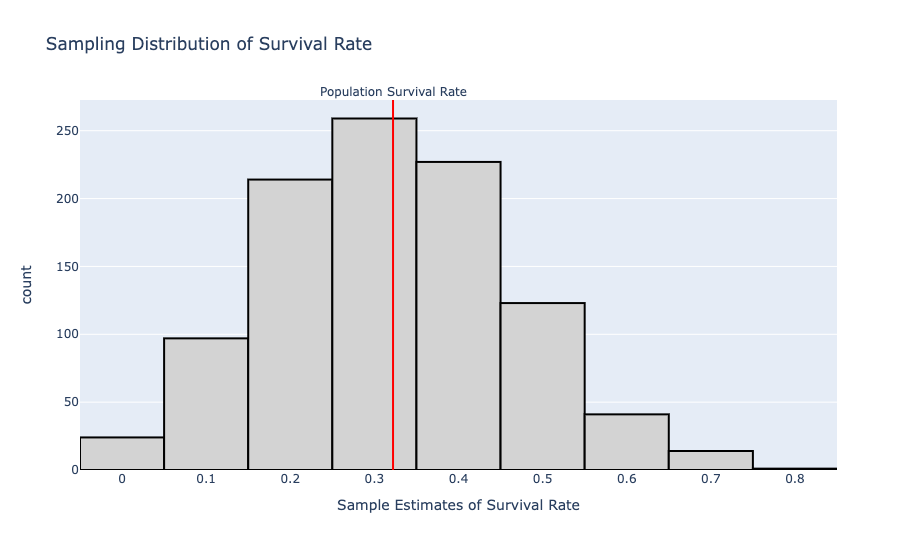

In [56]:
# Visualize the sample estimates
fig = px.histogram(sample_surv_rates,
                   title = "Sampling Distribution of Survival Rate",
                   labels = {"value":"Sample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

pop_surv_rate = titanic["survived"].value_counts(normalize = True).loc["yes"]
fig.add_vline(x = pop_surv_rate,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Survival Rate",      
              annotation_position="top")

The histogram above visualizes the **sampling distribution of *survival rate***. What does it tell us?
* The "bump" of the histogram is concentrated around the true, population survival rate. This tells us that if you take a sample at random, it's quite likely that you'll get one whose survival rate estimate is close to the population value.
* The tails of the histogram extend as low as 0 and as high as 0.8. This tells us we can get unlucky samples whose estimates are quite far from the true, population value.
* Estimation performance here doesn't seem too bad, especially given that the sample size was $n=10$ (less than 1\% of the population size).

This same information (and insights) can instead be visualized via the **sample error distribution** which is, as the name suggests, the distribution of sample errors.

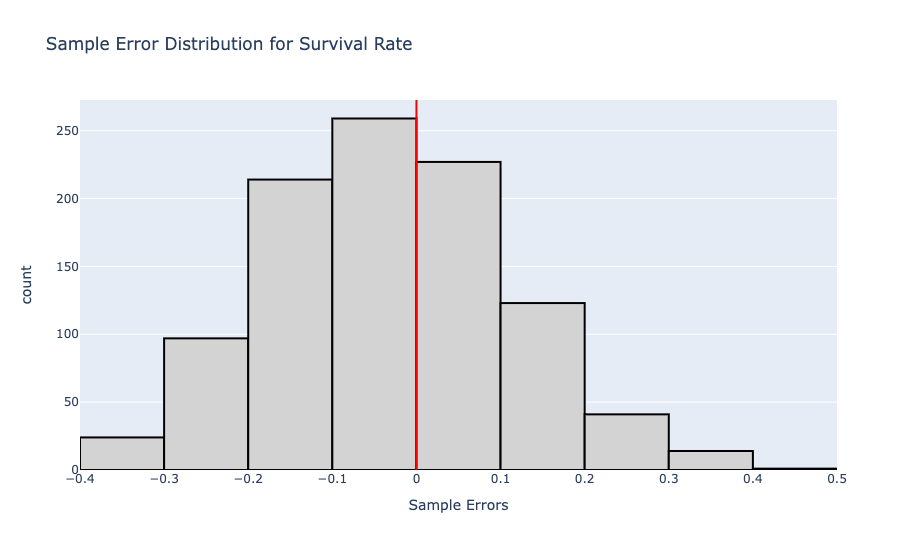

In [57]:
# Visualize the sample errors
sample_errors = sample_surv_rates - pop_surv_rate
fig = px.histogram(sample_errors,
                   title = "Sample Error Distribution for Survival Rate",
                   labels = {"value":"Sample Errors"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

pop_surv_rate = titanic["survived"].value_counts(normalize = True).loc["yes"]
fig.add_vline(x = 0,          
              line_width=2,            
              line_dash="solid",       
              line_color="red")

---

### Sampling Distribution of Average Age

We repeat the last exercise, but this time investigating *average age*. We again take 1000 simple random samples of size $n=10$ from the Titanic data. On each of them we'll calculate the *average age* and construct a histogram of those estimates. 

In [58]:
# Initialize an empty list that we'll fill with the 1000 average age estimates
sample_avg_ages = []

# Repeatedly sample and calculate average age estimates
for i in range(1000):
    sample = titanic.sample(n=10)
    avg_age = sample["age"].mean()
    sample_avg_ages.append(avg_age)

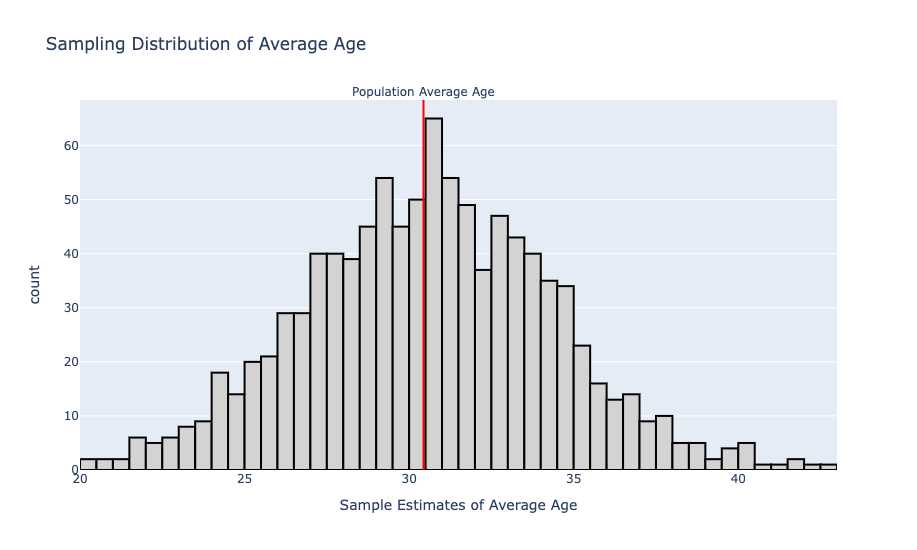

In [59]:
# Visualize the sample estimates
fig = px.histogram(sample_avg_ages,
                   title = "Sampling Distribution of Average Age",
                   labels = {"value":"Sample Estimates of Average Age"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

pop_avg_age = titanic["age"].mean()
fig.add_vline(x = pop_avg_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Average Age",      
              annotation_position="top")

The histogram above visualizes the **sampling distribution of *average age***. What does it tell us?
* The "bump" of the histogram is concentrated around the true, population average age. This tells us that if you take a sample at random, it's quite likely that you'll get one whose average age estimate is close to the population value.
* The tails of the histogram range roughly between 20 and 45. This tells us we can get unlucky samples whose estimates are quite far from the true, population value.
* Estimation performance here doesn't seem too bad, especially given that the sample size was $n=10$ (less than 1\% of the population size).

---

The sampling distributions we visualized above had two important things in common:
* The attribute being investigated was a mean
* The sample size was $n=10$

How does the sampling distribution behaviour change if we increase the sample size, or consider different attributes? We explore these questions next.

---
---
## The Effect of Sample Size

The sampling distribution investigations above considered very small samples. What do we expect to happen when we increase sample size?
* Will it change the *center* of the sampling distribution?
* Will it change the *spread* of the sampling distribution?
* Will it change the *shape* of the sampling distribution?

Let's find out.

---

### Sampling Distribution of Survival Rate

To illustrate the impact sample size has on a sampling distribution, we'll take 1000 simple random samples of size $n=\{10, 100, 1000\}$ from the Titanic data. On each of them we'll calculate the *survival rate* and construct histograms of those estimates. 

In [60]:
# Initialize empty lists that we'll fill with the 1000 survival rate estimates
sample_surv_rates_10 = []
sample_surv_rates_100 = []
sample_surv_rates_1000 = []

# Repeatedly take samples of size 10, calculating survival rate on each
for i in range(1000):
    sample = titanic.sample(n=10)
    surv_rate = sample["survived"].value_counts(normalize = True).get("yes", 0)
    sample_surv_rates_10.append(surv_rate)
    
# Repeatedly take samples of size 100, calculating survival rate on each
for i in range(1000):
    sample = titanic.sample(n=100)
    surv_rate = sample["survived"].value_counts(normalize = True).get("yes", 0)
    sample_surv_rates_100.append(surv_rate)
    
# Repeatedly take samples of size 1000, calculating survival rate on each
for i in range(1000):
    sample = titanic.sample(n=1000)
    surv_rate = sample["survived"].value_counts(normalize = True).get("yes", 0)
    sample_surv_rates_1000.append(surv_rate)

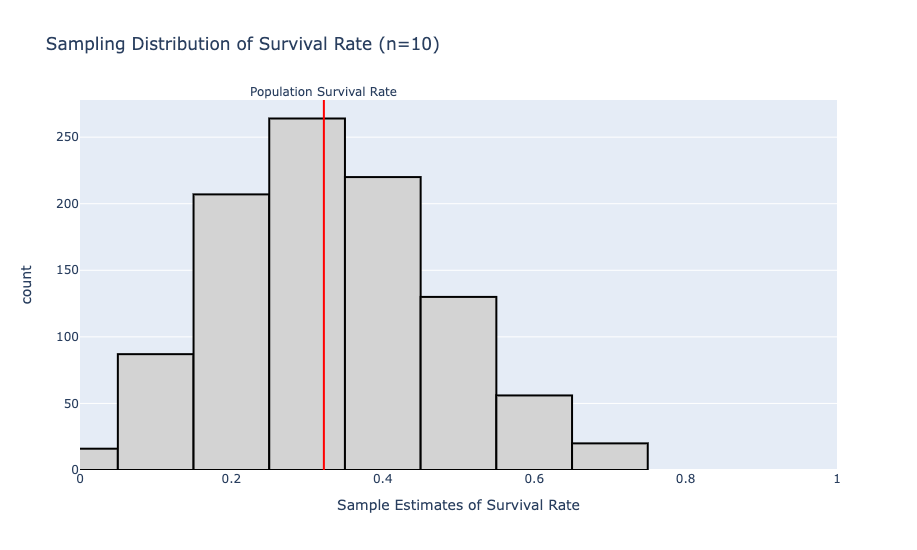

In [61]:
# Visualize the sample estimates
fig = px.histogram(sample_surv_rates_10,
                   title = "Sampling Distribution of Survival Rate (n=10)",
                   labels = {"value":"Sample Estimates of Survival Rate"},
                   height = 550,
                   range_x = [0,1])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_surv_rate,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Survival Rate",      
              annotation_position="top")

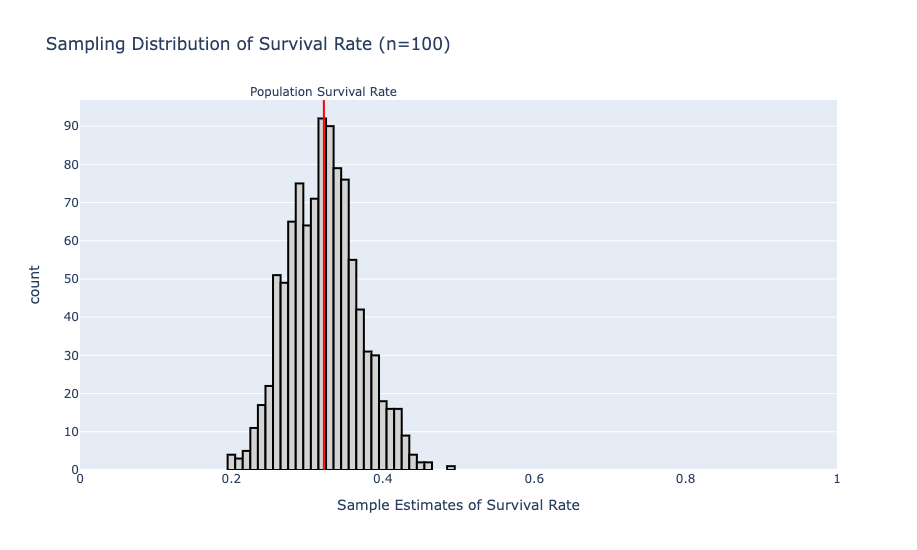

In [62]:
# Visualize the sample estimates
fig = px.histogram(sample_surv_rates_100,
                   title = "Sampling Distribution of Survival Rate (n=100)",
                   labels = {"value":"Sample Estimates of Survival Rate"},
                   height = 550,
                   range_x = [0,1])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_surv_rate,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Survival Rate",      
              annotation_position="top")

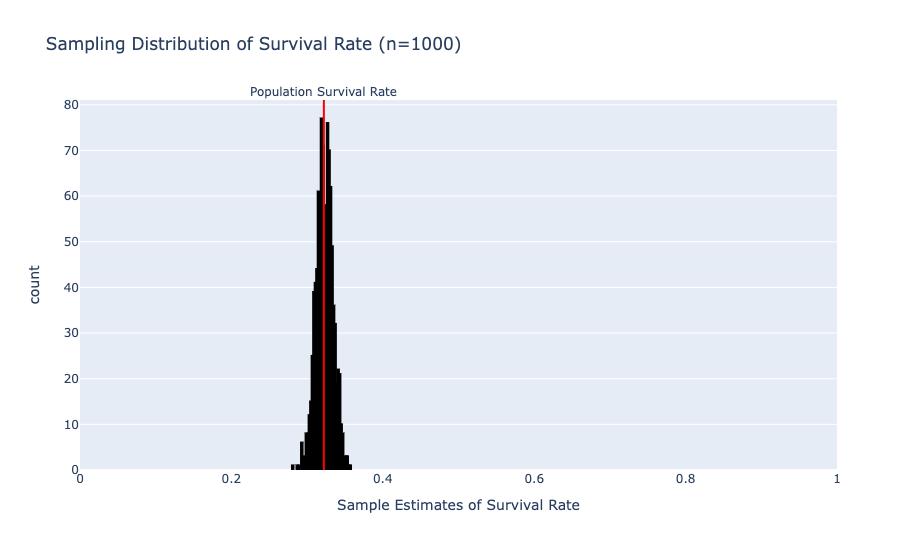

In [63]:
# Visualize the sample estimates
fig = px.histogram(sample_surv_rates_1000,
                   title = "Sampling Distribution of Survival Rate (n=1000)",
                   labels = {"value":"Sample Estimates of Survival Rate"},
                   height = 550,
                   range_x = [0,1])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_surv_rate,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Survival Rate",      
              annotation_position="top")

**What do we see?**
* All of the distributions are centered roughly around the true, population survival rate.
* The variability of survival rate estimates shrinks as sample size increases.
* The shape of the histograms are all relatively symmetric around the true value, no matter the sample size.

**What does this tell us?**
* If we take a sample at random, the larger that sample is, the more likely the estimate we calculate from it will be close to the true population value.

Let's see if we have similar insights with the *average age* attribute.

---

### Sampling Distribution of Average Age

Again we'll take 1000 simple random samples of size $n=\{10, 100, 1000\}$ from the Titanic data. This time, on each of them we'll calculate the *average age* and construct histograms of those estimates. 

In [64]:
# Initialize empty lists that we'll fill with the 1000 average age estimates
sample_avg_ages_10 = []
sample_avg_ages_100 = []
sample_avg_ages_1000 = []

# Repeatedly take samples of size 10, calculating average age on each
for i in range(1000):
    sample = titanic.sample(n=10)
    avg_age = sample["age"].mean()
    sample_avg_ages_10.append(avg_age)
    
# Repeatedly take samples of size 100, calculating average age on each
for i in range(1000):
    sample = titanic.sample(n=100)
    avg_age = sample["age"].mean()
    sample_avg_ages_100.append(avg_age)
    
# Repeatedly take samples of size 1000, calculating average age on each
for i in range(1000):
    sample = titanic.sample(n=1000)
    avg_age = sample["age"].mean()
    sample_avg_ages_1000.append(avg_age)

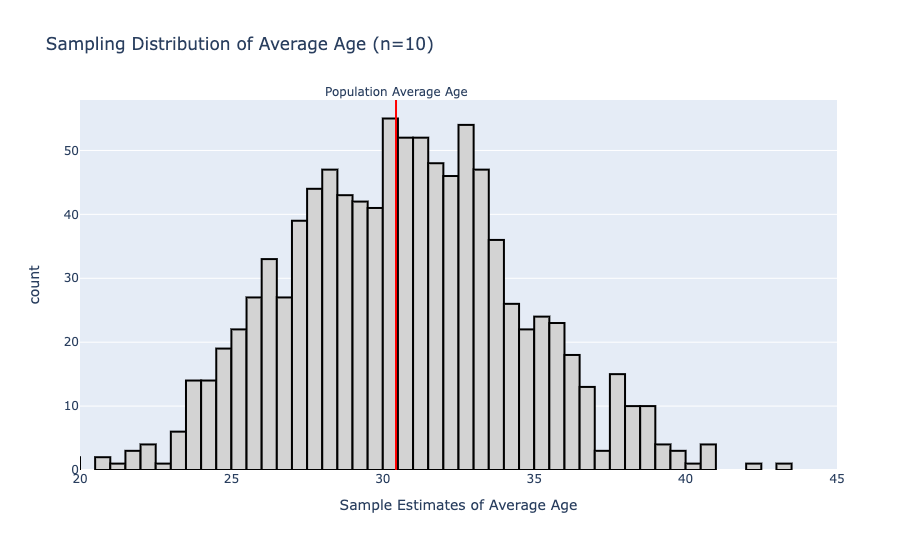

In [65]:
# Visualize the sample estimates
fig = px.histogram(sample_avg_ages_10,
                   title = "Sampling Distribution of Average Age (n=10)",
                   labels = {"value":"Sample Estimates of Average Age"},
                   height = 550,
                   range_x = [20,45])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_avg_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Average Age",      
              annotation_position="top")

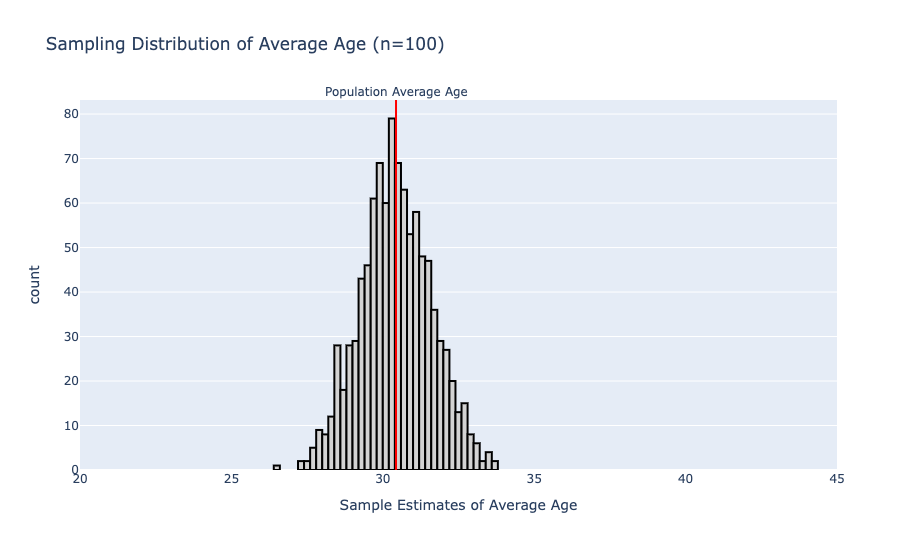

In [66]:
# Visualize the sample estimates
fig = px.histogram(sample_avg_ages_100,
                   title = "Sampling Distribution of Average Age (n=100)",
                   labels = {"value":"Sample Estimates of Average Age"},
                   height = 550,
                   range_x = [20,45])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_avg_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Average Age",      
              annotation_position="top")

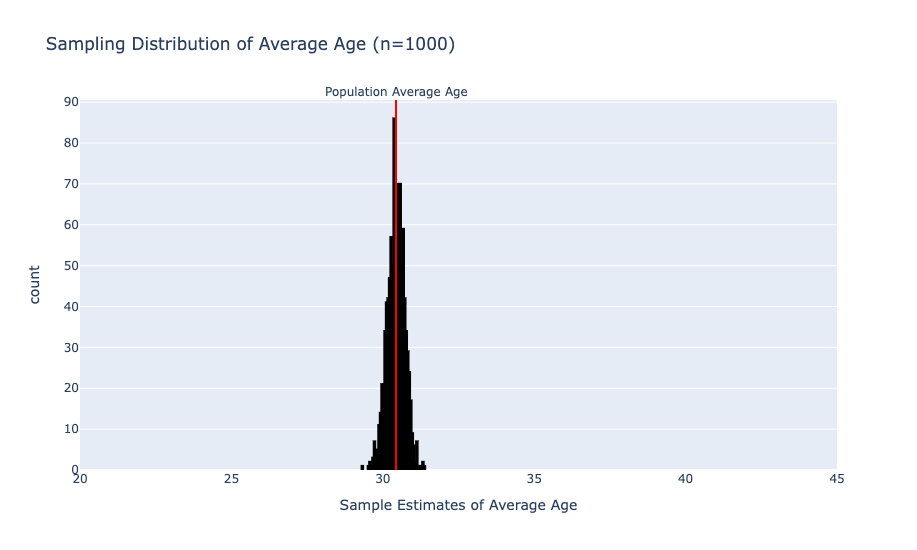

In [67]:
# Visualize the sample estimates
fig = px.histogram(sample_avg_ages_1000,
                   title = "Sampling Distribution of Average Age (n=1000)",
                   labels = {"value":"Sample Estimates of Average Age"},
                   height = 550,
                   range_x = [20,45])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_avg_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Average Age",      
              annotation_position="top")

**What do we see?**
* All of the distributions are centered roughly around the true, population average age.
* The variability of average age estimates shrinks as sample size increases.
* The shape of the histograms are all relatively symmetric around the true value, no matter the sample size.

**What does this tell us?**
* If we take a sample at random, the larger that sample is, the more likely the estimate we calculate from it will be close to the true population value.

These insights are qualitatively the same as what we saw with the survival rate sampling distributions. But, statistically speaking, *average age* is just another *mean* (*survival rate* was also a mean). So it's perhaps not surprising we'd see similar behaviour in these sampling distributions. 

**What if we considered an attribute other than the mean?**

---
---
## The Effect of Attribute

Below we repeat the same exercise as above, but with median age, the standard deviation of age, and the 99th percentile of age.

---

### Sampling Distribution of Median Age



In [68]:
# Initialize empty lists that we'll fill with the 1000 median age estimates
sample_med_ages_10 = []
sample_med_ages_100 = []
sample_med_ages_1000 = []

# Repeatedly take samples of size 10, calculating median age on each
for i in range(1000):
    sample = titanic.sample(n=10)
    med_age = sample["age"].median()
    sample_med_ages_10.append(med_age)
    
# Repeatedly take samples of size 100, calculating median age on each
for i in range(1000):
    sample = titanic.sample(n=100)
    med_age = sample["age"].median()
    sample_med_ages_100.append(med_age)
    
# Repeatedly take samples of size 1000, calculating median age on each
for i in range(1000):
    sample = titanic.sample(n=1000)
    med_age = sample["age"].median()
    sample_med_ages_1000.append(med_age)

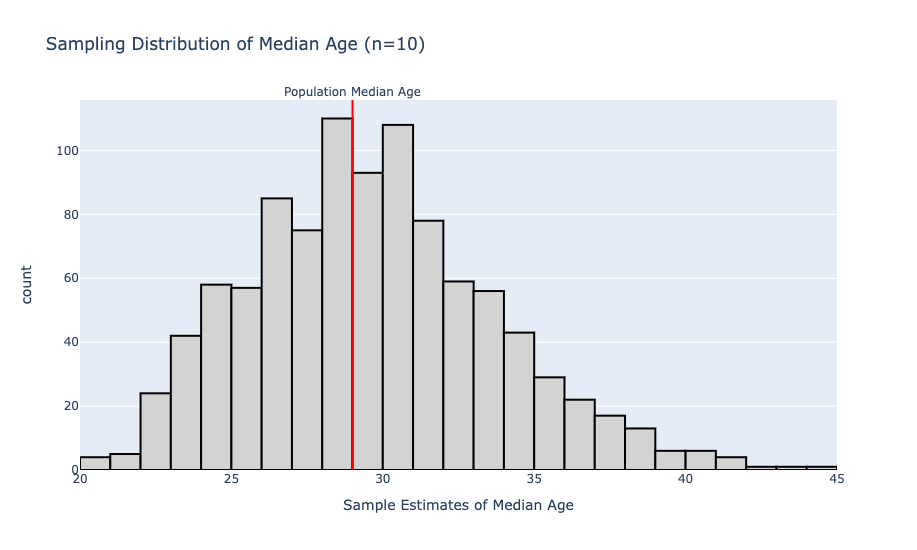

In [69]:
# Visualize the sample estimates
fig = px.histogram(sample_med_ages_10,
                   title = "Sampling Distribution of Median Age (n=10)",
                   labels = {"value":"Sample Estimates of Median Age"},
                   height = 550,
                   range_x = [20,45])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

pop_med_age = titanic["age"].median()
fig.add_vline(x = pop_med_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Median Age",      
              annotation_position="top")

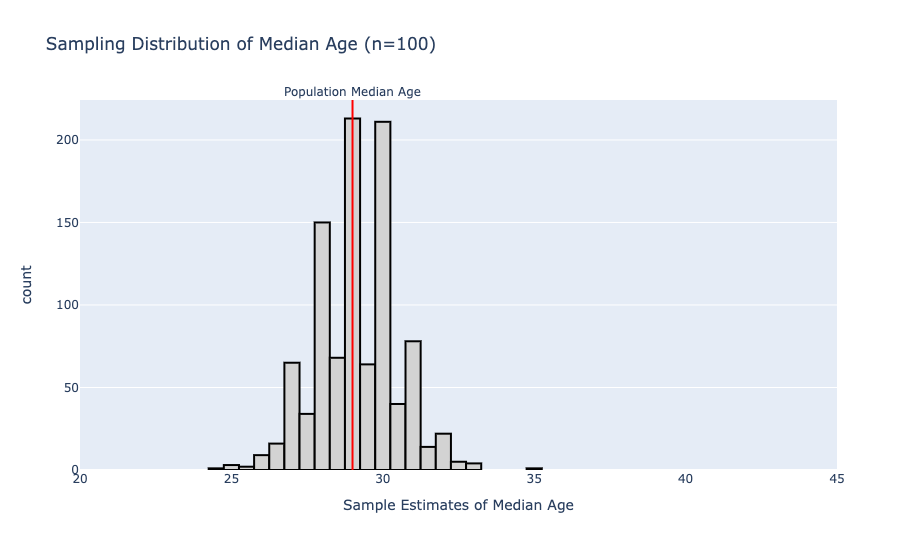

In [70]:
# Visualize the sample estimates
fig = px.histogram(sample_med_ages_100,
                   title = "Sampling Distribution of Median Age (n=100)",
                   labels = {"value":"Sample Estimates of Median Age"},
                   height = 550,
                   range_x = [20,45])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_med_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Median Age",      
              annotation_position="top")

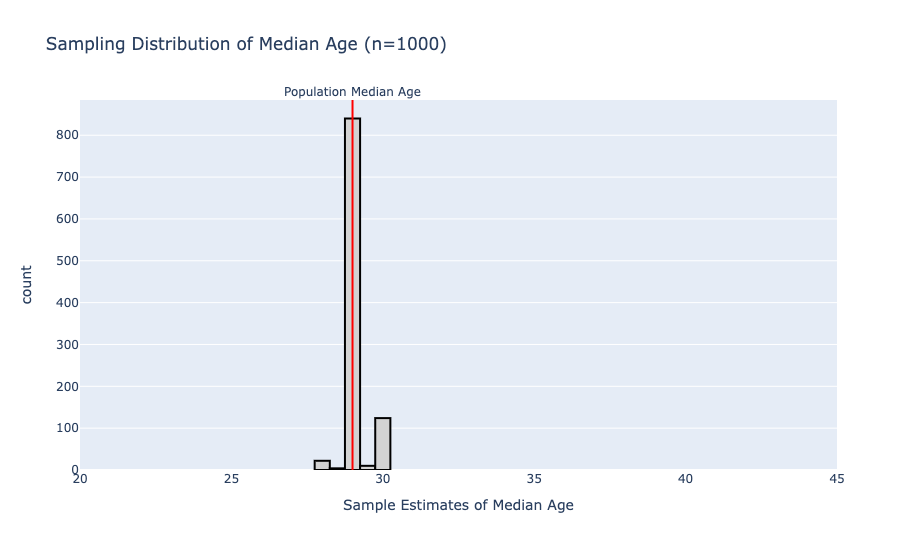

In [71]:
# Visualize the sample estimates
fig = px.histogram(sample_med_ages_1000,
                   title = "Sampling Distribution of Median Age (n=1000)",
                   labels = {"value":"Sample Estimates of Median Age"},
                   height = 550,
                   range_x = [20,45])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_med_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population Median Age",      
              annotation_position="top")

---

### Sampling Distribution of Standard Deviation of Age


In [72]:
# Initialize empty lists that we'll fill with the 1000 standard deviation estimates
sample_std_ages_10 = []
sample_std_ages_100 = []
sample_std_ages_1000 = []

# Repeatedly take samples of size 10, calculating standard deviation on each
for i in range(1000):
    sample = titanic.sample(n=10)
    std_age = sample["age"].std(ddof=0)
    sample_std_ages_10.append(std_age)
    
# Repeatedly take samples of size 100, calculating standard deviation on each
for i in range(1000):
    sample = titanic.sample(n=100)
    std_age = sample["age"].std(ddof=0)
    sample_std_ages_100.append(std_age)
    
# Repeatedly take samples of size 1000, calculating standard deviation on each
for i in range(1000):
    sample = titanic.sample(n=1000)
    std_age = sample["age"].std(ddof=0)
    sample_std_ages_1000.append(std_age)

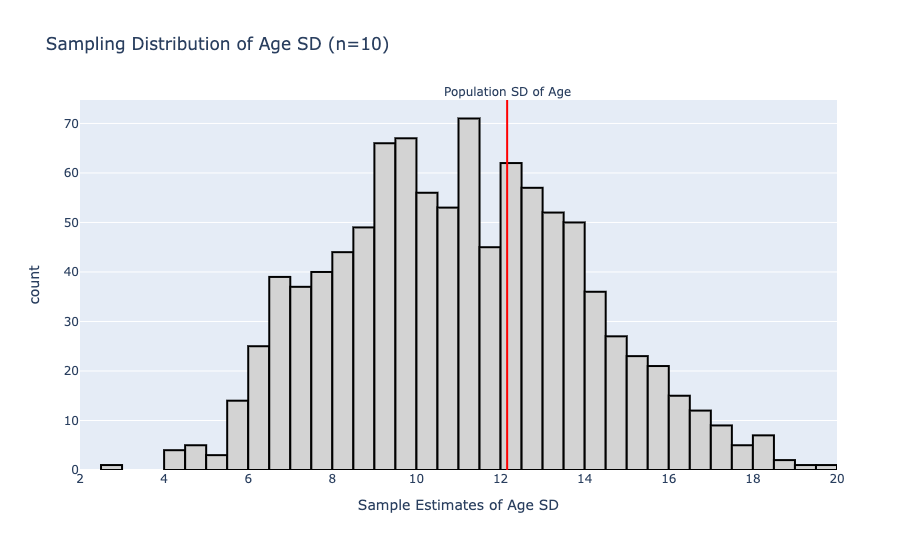

In [73]:
# Visualize the sample estimates
fig = px.histogram(sample_std_ages_10,
                   title = "Sampling Distribution of Age SD (n=10)",
                   labels = {"value":"Sample Estimates of Age SD"},
                   height = 550,
                   range_x = [2,20])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

pop_std_age = titanic["age"].std(ddof=0)
fig.add_vline(x = pop_std_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population SD of Age",      
              annotation_position="top")

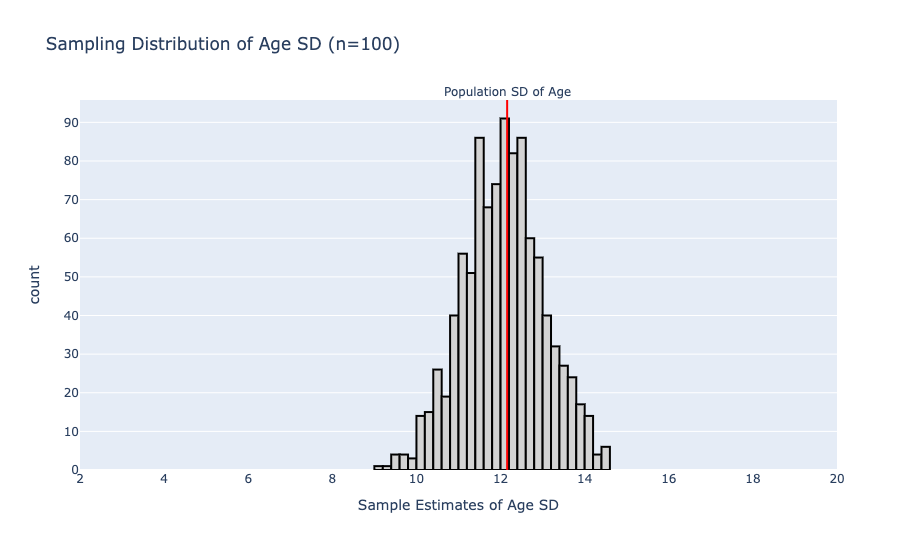

In [74]:
# Visualize the sample estimates
fig = px.histogram(sample_std_ages_100,
                   title = "Sampling Distribution of Age SD (n=100)",
                   labels = {"value":"Sample Estimates of Age SD"},
                   height = 550,
                   range_x = [2,20])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_std_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population SD of Age",      
              annotation_position="top")

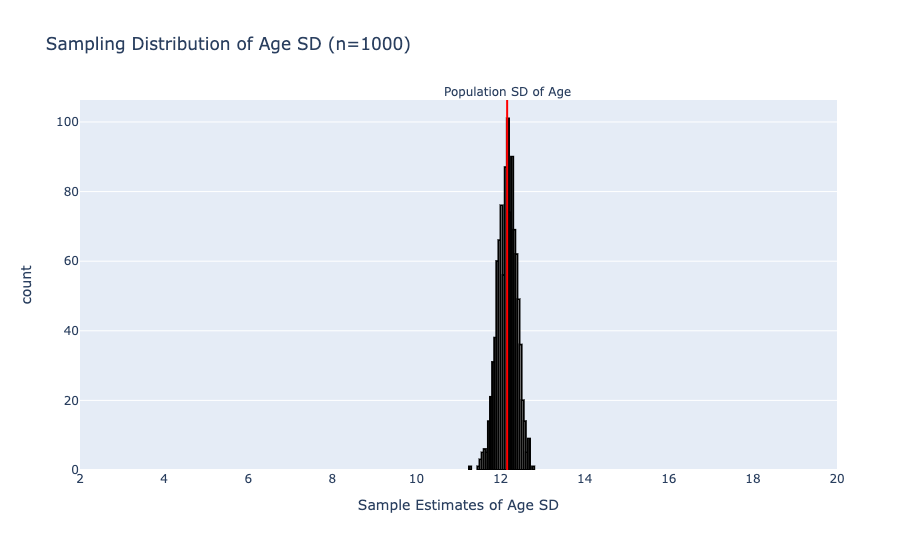

In [75]:
# Visualize the sample estimates
fig = px.histogram(sample_std_ages_1000,
                   title = "Sampling Distribution of Age SD (n=1000)",
                   labels = {"value":"Sample Estimates of Age SD"},
                   height = 550,
                   range_x = [2,20])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_std_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population SD of Age",      
              annotation_position="top")


---

### Sampling Distribution of 99th Percentile of Age

In [76]:
# Initialize empty lists that we'll fill with the 1000 99th percentile age estimates
sample_99p_ages_10 = []
sample_99p_ages_100 = []
sample_99p_ages_1000 = []

# Repeatedly take samples of size 10, calculating 99th percentile age on each
for i in range(1000):
    sample = titanic.sample(n=10)
    age_99p = sample["age"].quantile(0.99)
    sample_99p_ages_10.append(age_99p)
    
# Repeatedly take samples of size 100, calculating 99th percentile age on each
for i in range(1000):
    sample = titanic.sample(n=100)
    age_99p = sample["age"].quantile(0.99)
    sample_99p_ages_100.append(age_99p)
    
# Repeatedly take samples of size 1000, calculating 99th percentile age on each
for i in range(1000):
    sample = titanic.sample(n=1000)
    age_99p = sample["age"].quantile(0.99)
    sample_99p_ages_1000.append(age_99p)

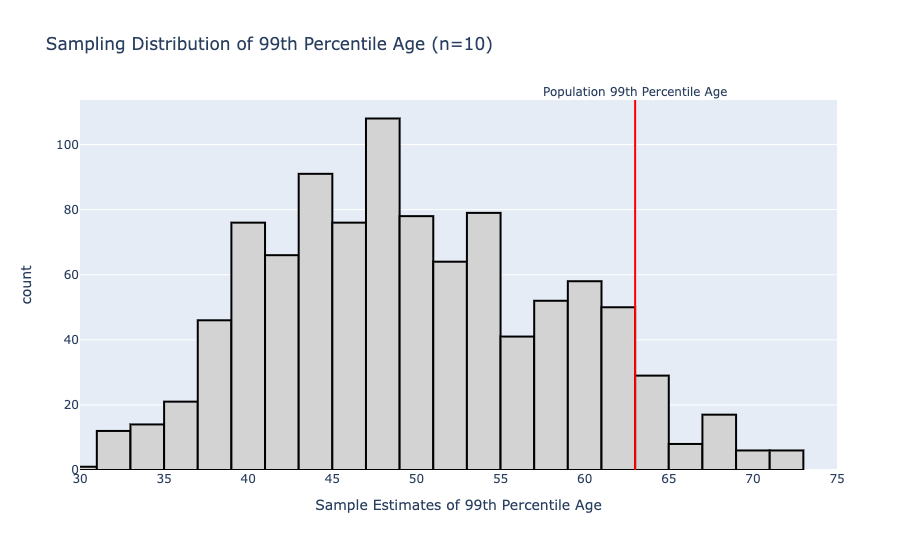

In [77]:
# Visualize the sample estimates
fig = px.histogram(sample_99p_ages_10,
                   title = "Sampling Distribution of 99th Percentile Age (n=10)",
                   labels = {"value":"Sample Estimates of 99th Percentile Age"},
                   height = 550,
                   range_x = [30,75])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

pop_99p_age = titanic["age"].quantile(0.99)
fig.add_vline(x = pop_99p_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population 99th Percentile Age",      
              annotation_position="top")

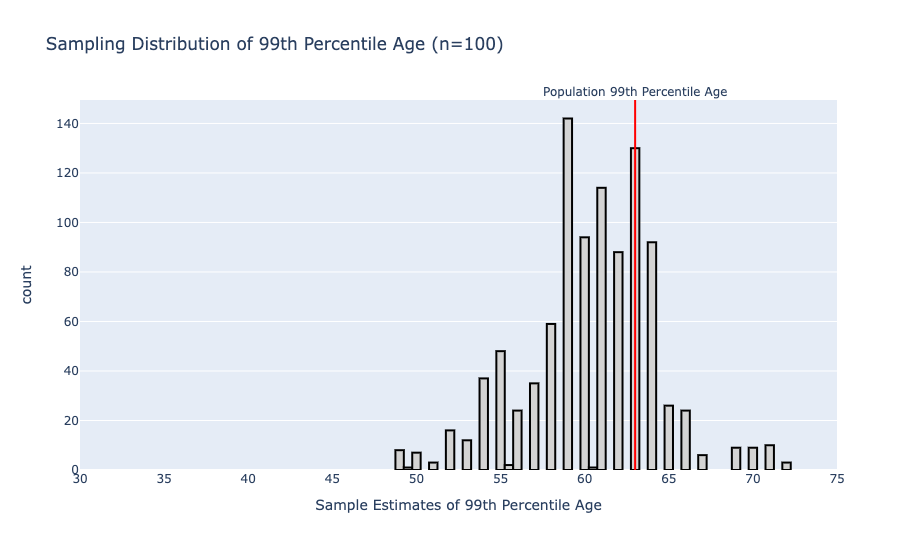

In [78]:
# Visualize the sample estimates
fig = px.histogram(sample_99p_ages_100,
                   title = "Sampling Distribution of 99th Percentile Age (n=100)",
                   labels = {"value":"Sample Estimates of 99th Percentile Age"},
                   height = 550,
                   range_x = [30,75])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_99p_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population 99th Percentile Age",      
              annotation_position="top")

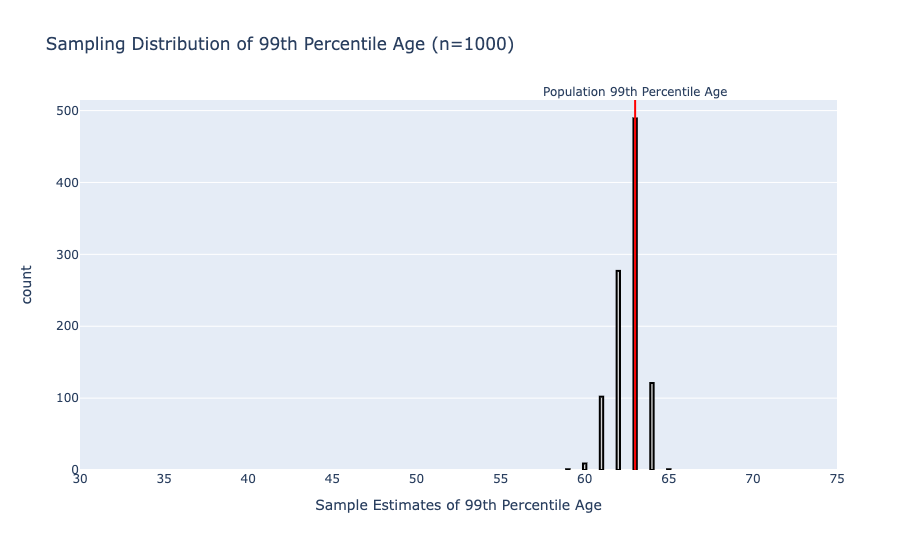

In [79]:
# Visualize the sample estimates
fig = px.histogram(sample_99p_ages_1000,
                   title = "Sampling Distribution of 99th Percentile Age (n=1000)",
                   labels = {"value":"Sample Estimates of 99th Percentile Age"},
                   height = 550,
                   range_x = [30,75])

fig.update_traces(showlegend = False,
                  marker_color = "lightgrey", 
                  marker_line_color = "black",
                  marker_line_width = 2)

fig.add_vline(x = pop_99p_age,          
              line_width=2,            
              line_dash="solid",       
              line_color="red",         
              annotation_text="Population 99th Percentile Age",      
              annotation_position="top")

---
---

## Key Takeaways

* Sample attributes may be used to estimate population attributes.
* Different factors influence whether a sample attribute is a *good* estimate of a population attribute (i.e., low sample error).
* Simple random samples produce representative samples.
* The larger the sample size, the better the estimate (i.e., lower sample error).
* If a population attribute is hard to capture in a sample (i.e., an extreme percentile), the sample attribute may be a poor estimate.

**In sum: large, random samples will produce the highest quality inference.**


---
---

## Where We Go From Here

The sampling distributions we explored gave us a good idea of where the population attribute is. And they provided helpful information about possible sample errors. But in practice, we only have one sample. So, what can we do in that case? The answer is to build proxy sampling distributions and calculate confidence intervals. But before we do that, we need to learn about **probability**.

---
---